In [1]:
#
# Author M. Kavatsyuk
#

# Load the relevant packages used in this notebook.

%matplotlib inline
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import scipy.integrate as integrate
#from numba import njit

In [2]:
# Define potential function
def V_pot(x,pars):
    """
    Function used to evaluate finite-well potential
    Parameters: Well_depth, Well_width
    
    """
    V0 = pars[0]
    a = pars[1]
    #
    res = np.array(x)
    condition = np.logical_and(x>-a/2,x<a/2)
    res[condition] = 0
    res[np.logical_not(condition)] = V0
    return res

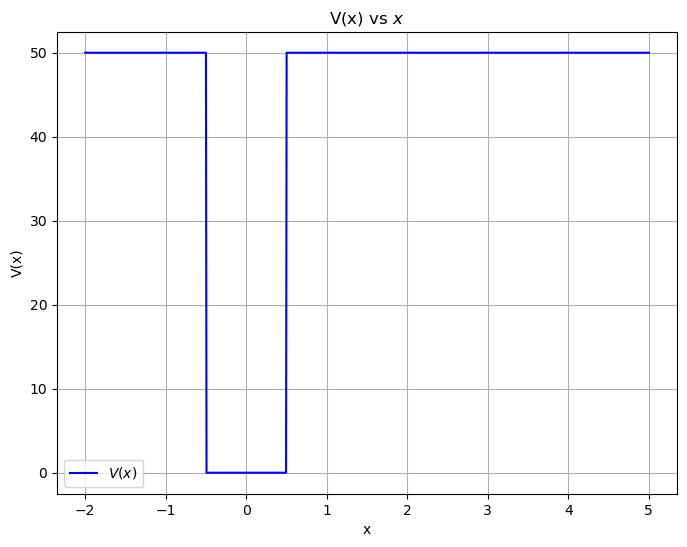

In [49]:
# plotting step potential
xlist_pl = np.linspace(-2, 5, 1000)

# plotting the results 
plt.figure(figsize=(8, 6))
plt.plot(xlist_pl,V_pot(xlist_pl,[50,1]) ,  color='b', label=r'$V(x)$')
plt.legend(loc='best')
plt.title(r'V(x) vs $x$')
plt.xlabel('x')
plt.ylabel(r'V(x)')
plt.grid('on')
plt.show()

In [4]:
# Derivative functions containing the ODE used by odeint solver
def der_psi(psivec, x, E, m, V_func, v_par):
    """
    Function used as input to odeint solver and it returns the array d(psivec[0],psivec[1])/dt, whereby
    
    psivec[0] - wave function psi
    psivec[1] - the derivative of psi
    x         - position
    E         - Energy value
    m         - mass of the particle
    V0        - height of the potential
    a         - width of the potential
    
    """
    hbar = 1
    psi, dpsidx = psivec
    return (dpsidx, -2*m/hbar**2 * (E - V_func(x,v_par)) * psi )

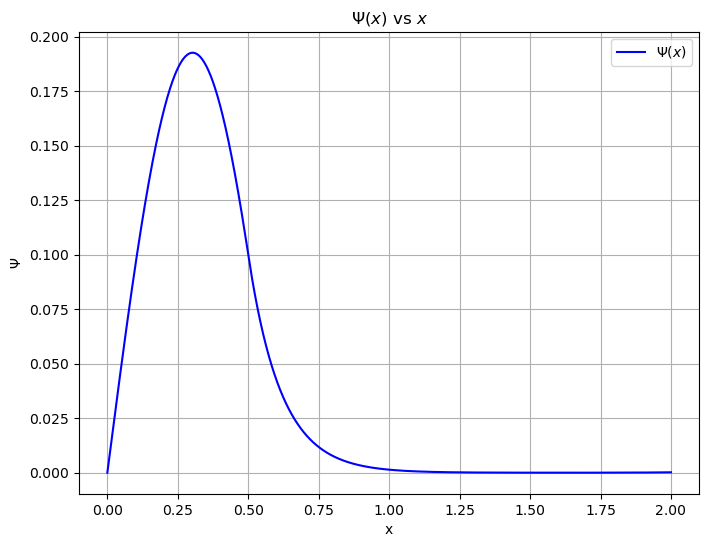

In [66]:
xmax = 2
V0   = 50
a    = 1
m    = 1

E0 = 13.47572281787313
#=========================================
xlist = np.linspace(0, xmax, 10000)
psiinit = (0, 1)        # initial conditions at -xmax: (starting psi, starting derivative of psi)
#
thexact  = integrate.odeint(der_psi,  psiinit, xlist, args=(E0,m,V_pot,[V0,a]))
# plotting the results 
plt.figure(figsize=(8, 6))
plt.plot(xlist, (thexact[:, 0]),  color='b', label=r'$\Psi(x)$')
plt.legend(loc='best')
plt.title(r'$\Psi(x)$ vs $x$')
plt.xlabel('x')
plt.ylabel(r'$\Psi$')
plt.grid('on')
plt.show()

In [7]:
# Find a level for the given potential above initial value

def find_level(E0,dE,xmax,m,V_func,v_par,accuracy=0.001,maxiter=500):
    """
    Returns found energy value. The function searches bound states
    only in the direction of increasing energies, starting with energy E0
    with initial step dE.
    Other parameters:
    xmax   -- waveform defined in the interval (-xmax,xmax)
    m      -- mass of the particle
    V_func -- Potential function
    v_par  -- additional parameters of the V_func
    
    """
    xlist = np.linspace(-xmax, xmax, 10000)
    psiinit = (0, 0.001)        # initial conditions at -xmax: (starting psi, starting derivative of psi)
    #
    Ecur = E0
    dEcur = dE
    psi_ede = 2*accuracy
    iteration = 0
    #
    # initial solution
    thexact  = integrate.odeint(der_psi,  psiinit, xlist, args=(Ecur,m,V_func,v_par))
    psi_e = thexact[-1, 0]
    sol_sign = 1
    if psi_e < 0:
        sol_sign = -1
    #
    #print("start with ",Ecur)
    while abs(psi_ede) > accuracy and iteration < maxiter:
        iteration = iteration+1
        # solve Ecur+dEcur
        thexact  = integrate.odeint(der_psi,  psiinit, xlist, args=(Ecur+dEcur,m,V_func,v_par))
        psi_ede = thexact[-1, 0]
        #print(iteration,Ecur,psi_e,psi_ede)
        if psi_ede*sol_sign > 0:
            # Ecur+dEcur still too low
            Ecur = Ecur+dEcur
        else:
            # Ecur+dEcur too high
            dEcur = dEcur/2
    
    return [Ecur,iteration,psi_ede]

In [60]:
V0 = 50
a = 1
m = 1
find_level(4,0.1,2,m,V_pot,[V0,a],accuracy=0.2,maxiter=2000)

[13.475722503662078, 122, np.float64(0.13924943664899883)]

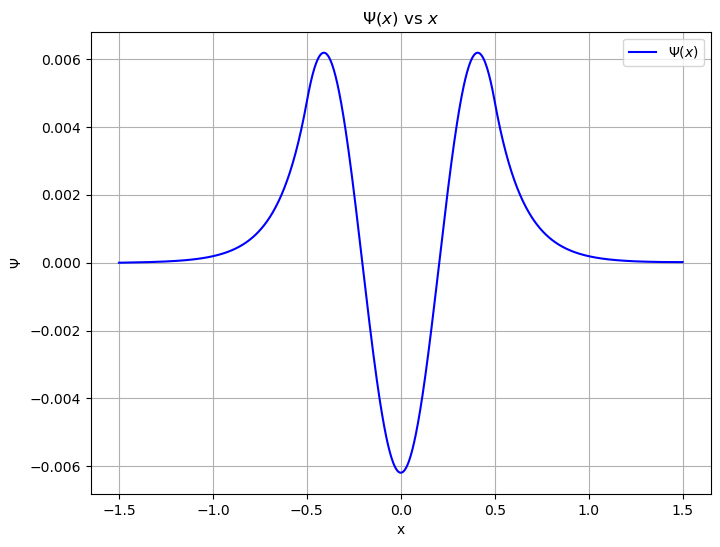

In [62]:
xmax = 1.5
V0   = 50
a    = 1
m    = 1

#E    = 3.413571028725336
E    = 13.47572281787313
E    = 29.452308230781856
#E    = 48.150000000000254
#E    = 5
#E = 4.3644261174534185

psiinit = (0, 0.0001)        # initial conditions at -xmax: (starting psi, starting derivative of psi)

# solving the ODEs for several positions given in array timelist
xlist = np.linspace(-xmax, xmax, 1000)
thexact  = integrate.odeint(der_psi,  psiinit, xlist, args=(E,m,V_pot,[V0,a]))

# plotting the results 
plt.figure(figsize=(8, 6))
plt.plot(xlist, (thexact[:, 0]),  color='b', label=r'$\Psi(x)$')
plt.legend(loc='best')
plt.title(r'$\Psi(x)$ vs $x$')
plt.xlabel('x')
plt.ylabel(r'$\Psi$')
plt.grid('on')
plt.show()

In [36]:
# Eigen function for infinite square well
def basis_inf_well(x,n,b):
    '''
    Evaluate n-th wave function at x for the ininite square well (0,b)
    
    '''
    res = np.zeros(np.size(x))
    condition = np.logical_and(x>0,x<b)
    if np.any(condition):
        res[condition] = np.sqrt(2.0/b) * np.sin(n*np.pi*x[condition]/b)
    return res

# Eigen values for infinite square well
def basis_inf_well_E(n,b):
    '''
    Evaluate n-th energy level for the ininite square well (0,b)
    
    '''
    return (np.pi*n/b)**2 /2

# Evaluate matrix element for given potential 
def V_matrix_element(n,m,V_func,v_pars,basis_func,range_width,v_pot_shift):
    '''
    Evaluate (n,m) matrix element for given potential V_func with additional
    parameters v_pars
    basis_func  -- wave function of the basis
    range_width -- Integration range [0,range_width]
    v_pos_shift -- shift for the V_pot position with respect to the integration range
    
    '''
    val, err = integrate.quad(
        lambda x: basis_func(np.array(x),n,range_width) *
        V_func(np.array(x-v_pot_shift),v_pars) *
        basis_func(np.array(x),m,range_width),
        0,range_width)
    return np.array([val, err])

# Evaluate matrix element for Hamiltonian
def H_matrix_element(n,m,V_func,v_pars,basis_func,range_width,v_pos_shift):
    '''
    Evaluate (n,m) matrix element for given potential V_func with additional
    parameters v_pars
    basis_func  -- wave function of the basis
    range_width -- Integration range [0,range_width]
    v_pos_shift -- shift for the V_pot position with respect to the integration range
    
    '''
    res = V_matrix_element(n,m,V_func,v_pars,basis_func,range_width,v_pos_shift)
    if n == m:
        res[0] = res[0] + basis_inf_well_E(n,range_width)
    return res

# Create symmetric hamiltonian matrix
def Create_Matrix(n,M_function):
    '''
    Retrns Hamiltonian matrix of (n,n) dimentions
    M_function -- Function used to calculate Hamiltonian matrix element
    
    '''
    matr = np.zeros([n,n])
    for i in range(n):
        for j in range(i,n):
            ij_val = M_function(i+1,j+1)
            matr[i,j] = ij_val
            matr[j,i] = ij_val
    return matr

# Evaluate wave function for solution
def WaveFunction(x,E_vector,range_width):
    res = np.zeros(np.size(x))
    sdim = np.size(E_vector)
    for i in range(sdim):
        res = res + E_vector[i] * basis_inf_well(x,i+1,range_width)
    return res

In [67]:
h_martrix = Create_Matrix(50,lambda n,m: H_matrix_element(n,m,V_pot,[50,1],basis_inf_well,4,2)[0])

In [68]:
# Solve Hamiltonian for eigen vectors and eigen values
E_values, E_vectors = sp.linalg.eigh(h_martrix)
# Check if eigen values and eigen vectors are correct
print("Max difference for eigen-values equation: ",
      np.max(h_martrix @ E_vectors[:,0] - E_values[0]*E_vectors[:,0]))
print("Energy levels: ",E_values)

Max difference for eigen-values equation:  3.9252889133534197e-14
Energy levels:  [  3.41565788  13.48237188  29.4697043   48.17036792  52.08022165
  52.90319666  57.99018037  59.93717944  66.77998294  70.5478789
  77.39559119  84.33935473  90.60154667 100.48968148 107.62795068
 118.0789321  128.00264859 137.82707009 150.54371416 161.20606663
 174.44878473 187.8214142  200.72408277 216.36489478 230.55939219
 246.41317119 263.28311669 279.23729683 297.69809383 315.48524916
 333.96709415 354.17130733 373.3518592  394.46617676 415.86163776
 437.10728897 460.41519138 483.01095478 506.75515309 531.60669892
 555.87411849 581.99165563 608.14390159 634.565308   662.8660797
 690.35242055 719.87719361 749.34329913 780.22507358 811.1791123 ]


In [39]:
np.max(h_martrix @ E_vectors[:,1] - E_values[1]*E_vectors[:,1])

np.float64(1.4921397450962104e-13)

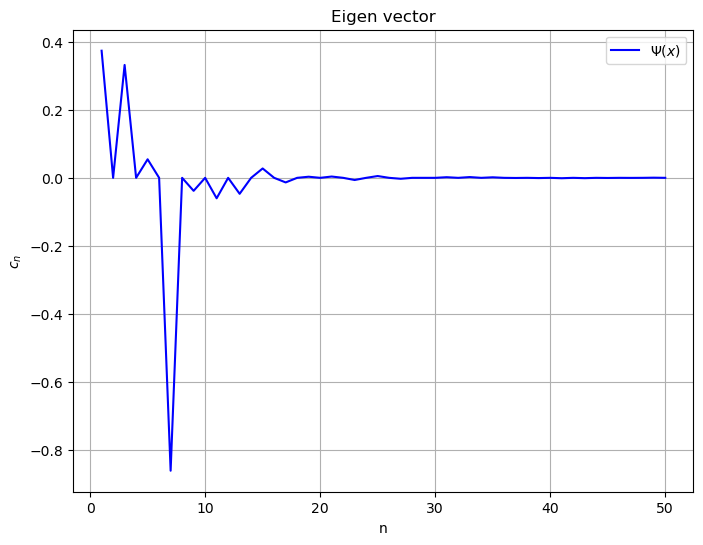

In [40]:
# plotting the eigen vector (weights)
vector_index = 4

plt.figure(figsize=(8, 6))
plt.plot(range(1,np.size(E_vectors[vector_index])+1),E_vectors[vector_index],  color='b', label=r'$\Psi(x)$')
plt.legend(loc='best')
plt.title('Eigen vector')
plt.xlabel('n')
plt.ylabel(r'$c_n$')
plt.grid('on')
plt.show()

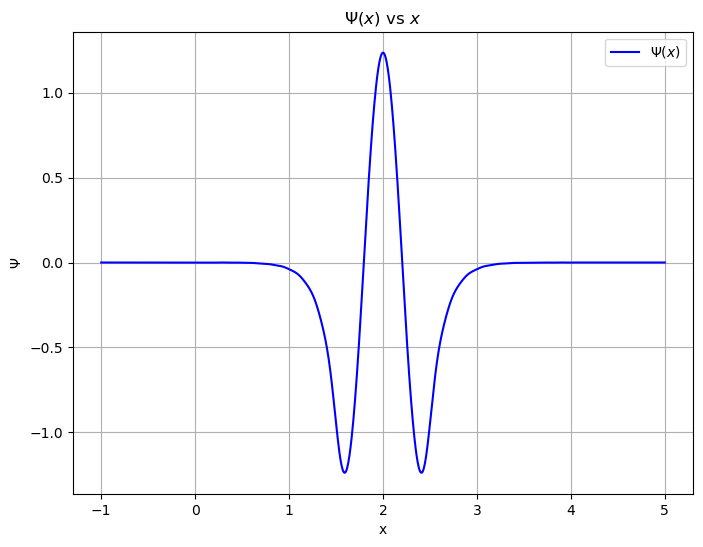

In [72]:
# plotting wavefunction
xlist_pl = np.linspace(-1, 5, 1000)

state_index = 2

# plotting the results 
plt.figure(figsize=(8, 6))
plt.plot(xlist_pl, WaveFunction(xlist_pl,E_vectors[:,state_index],4),  color='b', label=r'$\Psi(x)$')
plt.legend(loc='best')
plt.title(r'$\Psi(x)$ vs $x$')
plt.xlabel('x')
plt.ylabel(r'$\Psi$')
plt.grid('on')
plt.show()

In [42]:
# Define potential function
def V_pot_step(x,pars):
    """
    Function used to evaluate step potential:
    * 0 for x<a
    * V0 for x>0
    Parameters: Well_depth (V0), step position (a)
    
    """
    V0 = pars[0]
    a = pars[1]
    #
    #res = np.zeros(np.size(x))
    #condition = x>a
    #if np.any(condition):
    #    res[condition] = V0
    #    V0 = pars[0]
    #
    res = np.array(x)
    condition = x>a
    res[condition] = V0
    res[np.logical_not(condition)] = 0
    return res

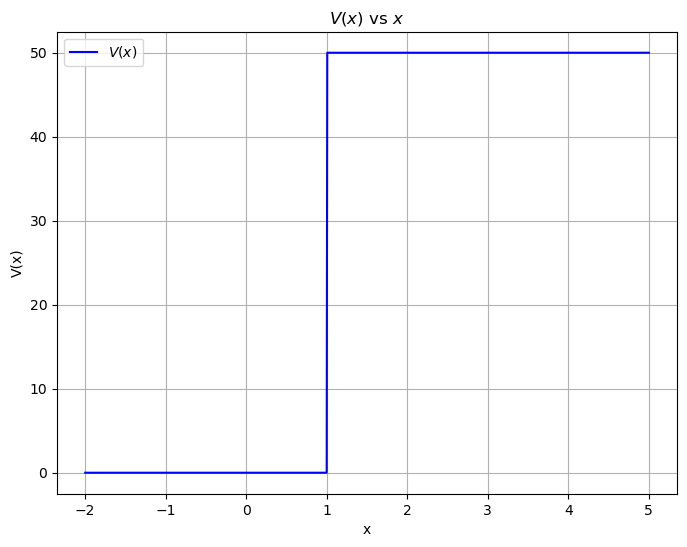

In [48]:
# plotting step potential
xlist_pl = np.linspace(-2, 5, 1000)

# plotting the results 
plt.figure(figsize=(8, 6))
plt.plot(xlist_pl,V_pot_step(xlist_pl,[50,1]) ,  color='b', label=r'$V(x)$')
plt.legend(loc='best')
plt.title(r'$V(x)$ vs $x$')
plt.xlabel('x')
plt.ylabel(r'V(x)')
plt.grid('on')
plt.show()

In [45]:
# The function taken from https://stackoverflow.com/questions/19910189/scipy-odeint-with-complex-initial-values
# better use odeintw from https://github.com/WarrenWeckesser/odeintw
def odeintz(func, z0, t, **kwargs):
    """An odeint-like function for complex valued differential equations."""

    # Disallow Jacobian-related arguments.
    _unsupported_odeint_args = ['Dfun', 'col_deriv', 'ml', 'mu']
    bad_args = [arg for arg in kwargs if arg in _unsupported_odeint_args]
    if len(bad_args) > 0:
        raise ValueError("The odeint argument %r is not supported by "
                         "odeintz." % (bad_args[0],))

    # Make sure z0 is a numpy array of type np.complex128.
    z0 = np.array(z0, dtype=np.complex128, ndmin=1)

    def realfunc(x, t, *args):
        z = x.view(np.complex128)
        dzdt = func(z, t, *args)
        # func might return a python list, so convert its return
        # value to an array with type np.complex128, and then return
        # a np.float64 view of that array.
        return np.asarray(dzdt, dtype=np.complex128).view(np.float64)

    result = integrate.odeint(realfunc, z0.view(np.float64), t, **kwargs)

    if kwargs.get('full_output', False):
        z = result[0].view(np.complex128)
        infodict = result[1]
        return z, infodict
    else:
        z = result.view(np.complex128)
        return z


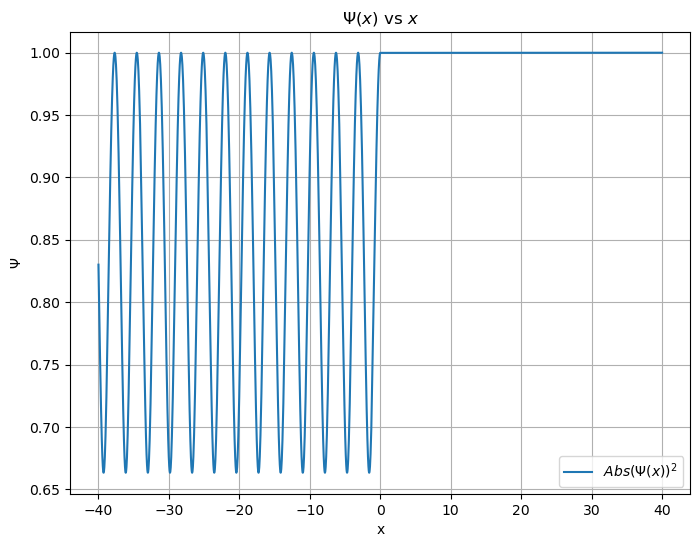

In [46]:
xmax = 40
V0   = 0.28
a    = 1
m    = 1

E    = 0.5

kp = np.sqrt(2*(E-V0))
psiinit = (1, kp*1j)        # initial conditions at -xmax: (starting psi, starting derivative of psi)

# solving the ODEs for several positions given in array timelist
xlist = np.linspace(xmax, -xmax, 10000)
thexact  = odeintz(der_psi,  psiinit, xlist, args=(E,m,V_pot_step,[V0,0]))

# plotting the results 
plt.figure(figsize=(8, 6))
#plt.plot(xlist, (thexact[:, 0].real),  label=r'$Re(\Psi(x))$')
#plt.plot(xlist, (thexact[:, 0].imag),  label=r'$Im(\Psi(x))$')
plt.plot(xlist, np.absolute(thexact[:, 0]),  label=r'$Abs(\Psi(x))^2$')
plt.legend(loc='best')
plt.title(r'$\Psi(x)$ vs $x$')
plt.xlabel('x')
plt.ylabel(r'$\Psi$')
plt.grid('on')
plt.show()